In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


Load & Prepare the Dataset

In [2]:
# Find the CSV in the existing data folder
data_dir = Path("../data")
csv_files = list(data_dir.glob("*.csv"))

if len(csv_files) != 1:
    raise ValueError(
        f"Expected one CSV file in {data_dir}, found: {csv_files}"
    )

df = pd.read_csv(csv_files[0])

# Clean blank strings and convert TotalCharges to numeric
df["TotalCharges"] = df["TotalCharges"].replace(
    r"^\s*$", np.nan, regex=True
)
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print("Dataset shape:", df.shape)
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("\nTarget distribution:")
print(df["Churn"].value_counts())
print("\nChurn proportions:")
print(df["Churn"].value_counts(normalize=True).round(4))

Dataset shape: (7043, 21)
Missing TotalCharges: 11

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn proportions:
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64


Separate Features & Targets

In [3]:
# Predict whether a customer will churn
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

if y.isna().any():
    raise ValueError("Unexpected values found in the Churn target.")

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

Feature matrix shape: (7043, 19)
Target shape: (7043,)

Features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


Split the data into Training & Testing Datasets

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training records: 5634
Testing records: 1409

Training churn rate: 26.54 %
Testing churn rate: 26.54 %


Build the Preprocessing Pipelines

In [5]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Preprocessing Steps

In [6]:
# Numeric: fill missing values, then standardize the values
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical: fill missing values, then convert categories to numbers
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate processing to each feature type
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Training First Baseline Model

In [7]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Baseline Logistic Regression model trained successfully!")

Baseline Logistic Regression model trained successfully!


Evaluate Model Performance

In [8]:
# Predictions for the test set
y_pred = model.predict(X_test)

# Probability of churn, needed for ROC-AUC
y_proba = model.predict_proba(X_test)[:, 1]

# Calculate metrics
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
}

print("Baseline Model Results")
for metric, score in metrics.items():
    print(f"{metric}: {score:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

Baseline Model Results
Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1-score: 0.6040
ROC-AUC: 0.8419

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



Confusion Matrix

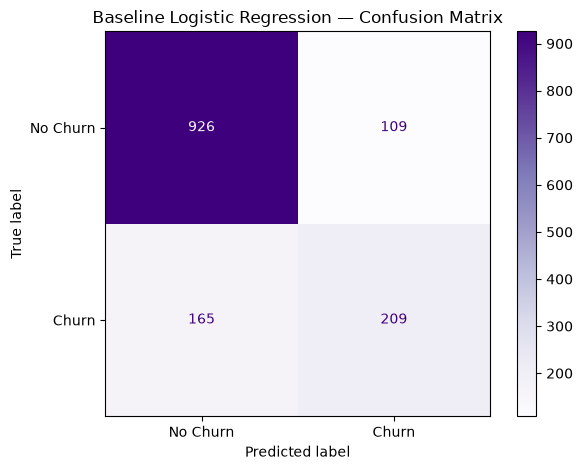

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Purples"
)

plt.title("Baseline Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

Save the Evaluation Metrics

In [10]:
results = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Score"]
)

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(
    reports_dir / "baseline_model_metrics.csv",
    index=False
)

print("Saved:", reports_dir / "baseline_model_metrics.csv")
display(results.round(4))

Saved: ..\reports\baseline_model_metrics.csv


,Metric,Score
0,Accuracy,0.8055
1,Precision,0.6572
2,Recall,0.5588
3,F1-score,0.6040
4,ROC-AUC,0.8419


Numeric Confusion Matrix

In [11]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

print("True Negatives (correctly predicted no churn):", tn)
print("False Positives (incorrectly predicted churn):", fp)
print("False Negatives (missed churners):", fn)
print("True Positives (correctly detected churners):", tp)

True Negatives (correctly predicted no churn): 926
False Positives (incorrectly predicted churn): 109
False Negatives (missed churners): 165
True Positives (correctly detected churners): 209


Adjust the Precision Threshold

In [12]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Reuse the probabilities from your trained model
y_proba = model.predict_proba(X_test)[:, 1]

for threshold in [0.50, 0.40, 0.30, 0.25]:
    y_threshold = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_threshold, labels=[0, 1]
    ).ravel()

    print(f"\nThreshold: {threshold:.2f}")
    print(f"Precision: {precision_score(y_test, y_threshold):.3f}")
    print(f"Recall:    {recall_score(y_test, y_threshold):.3f}")
    print(f"F1-score:  {f1_score(y_test, y_threshold):.3f}")
    print(f"False negatives: {fn}")
    print(f"False positives: {fp}")


Threshold: 0.50
Precision: 0.657
Recall:    0.559
F1-score:  0.604
False negatives: 165
False positives: 109

Threshold: 0.40
Precision: 0.569
Recall:    0.668
F1-score:  0.615
False negatives: 124
False positives: 189

Threshold: 0.30
Precision: 0.519
Recall:    0.754
F1-score:  0.615
False negatives: 92
False positives: 261

Threshold: 0.25
Precision: 0.498
Recall:    0.810
F1-score:  0.617
False negatives: 71
False positives: 305


Threshold Comparison Report

In [13]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

y_proba = model.predict_proba(X_test)[:, 1]
thresholds = [0.50, 0.40, 0.30, 0.25]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, y_pred_threshold),
        "recall": recall_score(y_test, y_pred_threshold),
        "f1_score": f1_score(y_test, y_pred_threshold),
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
    })

threshold_df = pd.DataFrame(results)
threshold_df

,threshold,precision,recall,f1_score,true_negatives,false_positives,false_negatives,true_positives
0,0.50,0.657233,0.558824,0.604046,926,109,165,209
1,0.40,0.569476,0.668449,0.615006,846,189,124,250
2,0.30,0.519337,0.754011,0.615049,774,261,92,282
3,0.25,0.498355,0.810160,0.617108,730,305,71,303


Save the Report

In [14]:
from pathlib import Path

report_dir = Path("../reports")
report_dir.mkdir(parents=True, exist_ok=True)

threshold_df.to_csv(
    report_dir / "threshold_comparison.csv",
    index=False
)

print("Threshold comparison saved successfully.")

Threshold comparison saved successfully.


Model Evaluation & Error Analysis

In [15]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Load dataset
data_dir = Path("../data")
csv_files = list(data_dir.glob("*.csv"))

if len(csv_files) != 1:
    raise ValueError(f"Expected one CSV file, found {len(csv_files)}")

df = pd.read_csv(csv_files[0])

# Clean blank TotalCharges values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Separate features and target
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Recreate the same stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Identify feature types
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Build and train the model
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Model trained successfully!")

Training rows: 5634
Testing rows: 1409
Model trained successfully!


In [16]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import matplotlib.pyplot as plt

# Predict churn classes and probabilities
y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")
print("Number of test predictions:", len(y_pred))
print("First 10 predicted classes:", y_pred[:10])
print("First 10 churn probabilities:", np.round(y_prob[:10], 3))

Predictions generated successfully!
Number of test predictions: 1409
First 10 predicted classes: [0 1 0 0 0 1 0 0 0 0]
First 10 churn probabilities: [0.045 0.684 0.059 0.402 0.022 0.604 0.449 0.13  0.003 0.395]


Evaluate the Model Using Key Metrics

In [17]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Score"]
)

metrics_df["Score"] = metrics_df["Score"].round(4)
display(metrics_df)

,Metric,Score
0,Accuracy,0.8055
1,Precision,0.6572
2,Recall,0.5588
3,F1 Score,0.6040
4,ROC-AUC,0.8419


Create and Interpret the Confusion Metrix 

Confusion Matrix:
[[926 109]
 [165 209]]


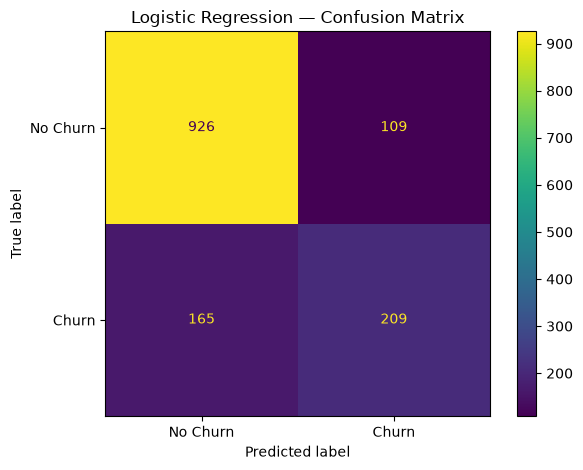

In [18]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot(values_format="d")

plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

Generate the Classification Report

In [19]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Churn     0.8488    0.8947    0.8711      1035
       Churn     0.6572    0.5588    0.6040       374

    accuracy                         0.8055      1409
   macro avg     0.7530    0.7268    0.7376      1409
weighted avg     0.7979    0.8055    0.8002      1409



plot the ROC curve

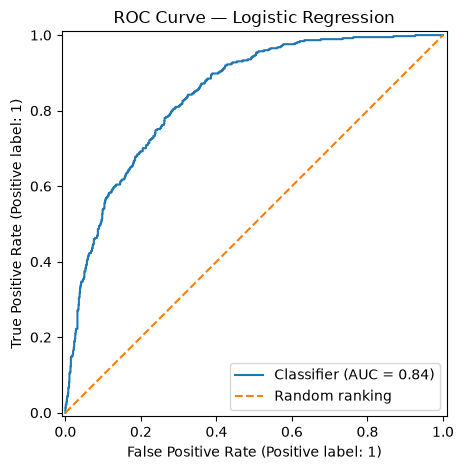

In [20]:
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random ranking"
)

plt.title("ROC Curve — Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()

Study the Decision Threshold

In [21]:
thresholds = [0.50, 0.40, 0.30, 0.25]

threshold_results = []

for threshold in thresholds:
    threshold_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, threshold_pred, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, threshold_pred),
        "precision": precision_score(
            y_test, threshold_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, threshold_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, threshold_pred, zero_division=0
        ),
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,threshold,accuracy,precision,recall,f1_score,true_negatives,false_positives,false_negatives,true_positives
0,0.50,0.8055,0.6572,0.5588,0.6040,926,109,165,209
1,0.40,0.7779,0.5695,0.6684,0.6150,846,189,124,250
2,0.30,0.7495,0.5193,0.7540,0.6150,774,261,92,282
3,0.25,0.7331,0.4984,0.8102,0.6171,730,305,71,303


Visualize the Threshold Tradeoffs

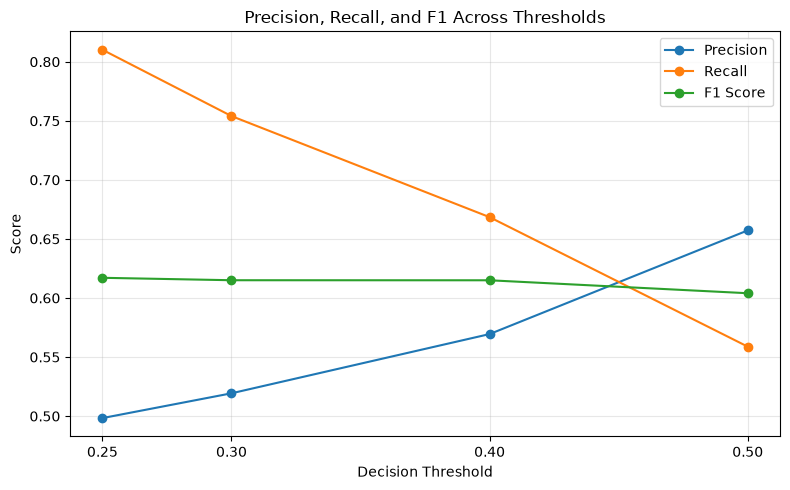

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1_score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall, and F1 Across Thresholds")
plt.xticks(thresholds)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Inspect the Individual Prediction Errors

In [23]:
error_analysis = X_test.copy()

error_analysis["actual_churn"] = y_test
error_analysis["predicted_churn"] = y_pred
error_analysis["churn_probability"] = y_prob

error_analysis["prediction_result"] = np.select(
    [
        (y_test.to_numpy() == 0) & (y_pred == 0),
        (y_test.to_numpy() == 1) & (y_pred == 1),
        (y_test.to_numpy() == 0) & (y_pred == 1),
        (y_test.to_numpy() == 1) & (y_pred == 0)
    ],
    [
        "True Negative",
        "True Positive",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)

misclassified = error_analysis[
    error_analysis["actual_churn"]
    != error_analysis["predicted_churn"]
].copy()

print("Total misclassified customers:", len(misclassified))
display(
    misclassified[
        [
            "tenure",
            "Contract",
            "MonthlyCharges",
            "TotalCharges",
            "actual_churn",
            "predicted_churn",
            "churn_probability",
            "prediction_result"
        ]
    ].head(15)
)

Total misclassified customers: 274


,tenure,Contract,MonthlyCharges,TotalCharges,actual_churn,predicted_churn,churn_probability,prediction_result
2280,8,Month-to-month,100.15,908.55,0,1,0.684411,False Positive
5748,21,Month-to-month,99.85,1992.55,0,1,0.603935,False Positive
1639,17,Month-to-month,45.05,770.60,1,0,0.395179,False Negative
2136,15,Month-to-month,91.00,1430.05,0,1,0.636600,False Positive
950,2,Month-to-month,44.95,85.15,1,0,0.376774,False Negative
2488,31,Month-to-month,55.25,1715.65,1,0,0.184399,False Negative
2519,2,Month-to-month,91.45,171.45,0,1,0.786970,False Positive
3510,8,Month-to-month,75.25,576.70,0,1,0.710109,False Positive
523,23,Month-to-month,75.60,1758.60,1,0,0.411362,False Negative
5086,45,One year,20.40,930.45,1,0,0.030107,False Negative


Summarize Error by Category

In [24]:
error_summary = (
    misclassified["prediction_result"]
    .value_counts()
    .rename_axis("error_type")
    .reset_index(name="count")
)

display(error_summary)

,error_type,count
0,False Negative,165
1,False Positive,109


Error Against "Contract-Types"

In [25]:
contract_error_summary = pd.crosstab(
    misclassified["Contract"],
    misclassified["prediction_result"]
)

display(contract_error_summary)

prediction_result,False Negative,False Positive
Contract,,
Month-to-month,120,109
One year,36,0
Two year,9,0


Save Ecaluation Report

In [26]:
report_dir = Path("../reports")
report_dir.mkdir(parents=True, exist_ok=True)

# Save metric scores
metrics_df.to_csv(
    report_dir / "day5_evaluation_metrics.csv",
    index=False
)

# Save threshold comparison
threshold_df.to_csv(
    report_dir / "day5_threshold_comparison.csv",
    index=False
)

# Save confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=["Actual_No_Churn", "Actual_Churn"],
    columns=["Predicted_No_Churn", "Predicted_Churn"]
)

cm_df.to_csv(report_dir / "day5_confusion_matrix.csv")

# Save misclassified customer records
misclassified.to_csv(
    report_dir / "day5_misclassified_customers.csv",
    index=True
)

print("Day 5 reports saved successfully:")
for filename in [
    "day5_evaluation_metrics.csv",
    "day5_threshold_comparison.csv",
    "day5_confusion_matrix.csv",
    "day5_misclassified_customers.csv"
]:
    print(report_dir / filename)

Day 5 reports saved successfully:
..\reports\day5_evaluation_metrics.csv
..\reports\day5_threshold_comparison.csv
..\reports\day5_confusion_matrix.csv
..\reports\day5_misclassified_customers.csv


## Model Evaluation and Error Analysis

### Key Findings
- Evaluated the Logistic Regression baseline using accuracy,
  precision, recall, F1 score, and ROC-AUC.
- Used the confusion matrix to distinguish false positives
  from false negatives.
- Examined how different decision thresholds affect precision,
  recall, and the number of missed churners.
- Inspected misclassified customer records to identify possible
  patterns for further investigation.

### Business Interpretation
A lower decision threshold can help identify more potential
churners, but may also increase false positives and the cost
of retention campaigns. The threshold should be chosen based
on business costs and validated on separate data.

### Limitations
- Evaluation is based on a single train-test split.
- Threshold selection requires validation data to avoid
  tuning directly to test-set results.
- Observed relationships do not establish causation.
- Model performance may vary across customer segments.

